##### Feladat (Példatár 1.25)

Egy törtvonalú tartó terheléseit és méreteit mutatja az alábbi ábra. A tartó keresztmetszete állandó, $d = 30 ~\mathrm{mm}$ átmérőjű kör. Határozza meg a befogás keresztmetszetében az igénybevételekből adódó feszültségeloszlásokat, valamint ábrázolja a $P_1 - P_5$ pontokban a feszültségeket!

<img src="img/01.jpg" alt="Feladat" width=600px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
L1 = 3 # m
L2 = 2 # m
p = 40 # N/m
d = 30 # mm

F_C = sp.Matrix([-150, 200, -50]) # N

#### Erőrendszer redukálása $A$-ba

##### Helyvektorok

In [3]:
r_AB = sp.Matrix([L1, 0, 0]) # m
r_AC = sp.Matrix([L1, 0, -L2]) # m

# A megoszló terhelés eredőjének támadáspontja (BC szakasz közepe)
r_AP = (r_AB + r_AC) / 2
display(Math(rf'\mathbf{{r}}_{{AP}} = \frac{{1}}{{2}} \left( \mathbf{{r}}_{{AB}} + \mathbf{{r}}_{{AC}} \right) = {latex(r_AP)} ~\mathrm{{m}}'))

<IPython.core.display.Math object>

##### Megoszló terhelés eredője

In [4]:
F_p = p * L2 * sp.Matrix([0, -1, 0])
display(Math(rf'\mathbf{{F}}_{{p}} = p \cdot L_2 \cdot (-\mathbf{{j}}) = {latex(F_p)} ~\mathrm{{N}}'))

<IPython.core.display.Math object>

##### Redukált vektorkettős $A$-ban

In [5]:
# Eredő erő
F = F_C + F_p
display(Math(rf'\mathbf{{F}} = \mathbf{{F}}_{{C}} + \mathbf{{F}}_{{p}} = {latex(F)} ~\mathrm{{N}}'))

# Eredő nyomaték
M_A = r_AC.cross(F_C) + r_AP.cross(F_p)
display(Math(rf'\mathbf{{M}}_{{A}} = \mathbf{{r}}_{{AC}} \times \mathbf{{F}}_{{C}} + \mathbf{{r}}_{{AP}} \times \mathbf{{F}}_{{p}} = {latex(M_A)} ~\mathrm{{Nm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### A befogott keresztmetszet igénybevételei

Az igénybevételek értelmét az ábra jelöli!

<img src="img/02.jpg" alt="Feladat" width=500px>

In [6]:
# Erő jellegű igénybevételek
N = sp.Abs(F[0]) # N
V_y = sp.Abs(F[1]) # N
V_z = sp.Abs(F[2]) # N

display(Math(rf'N = {latex(N)} ~\mathrm{{N}}'))
display(Math(rf'V_y = {latex(V_y)} ~\mathrm{{N}}'))
display(Math(rf'V_z = {latex(V_z)} ~\mathrm{{N}}'))

# Nyomaték jellegű igénybevételek
M_t = sp.Abs(M_A[0]) # Nm
M_hy = sp.Abs(M_A[1]) # Nm
M_hz = sp.Abs(M_A[2]) # Nm

display(Math(rf'M_t = {latex(M_t)} ~\mathrm{{Nm}}'))
display(Math(rf'M_{{hy}} = {latex(M_hy)} ~\mathrm{{Nm}}'))
display(Math(rf'M_{{hz}} = {latex(M_hz)} ~\mathrm{{Nm}}'))

# Átváltás N, mm, MPa rendszerbe
M_t = M_t * 10**3 # Nmm
M_hy = M_hy * 10**3 # Nmm
M_hz = M_hz * 10**3 # Nmm

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Keresztmetszeti jellemzők

In [7]:
r = d/2

A = d**2*sp.pi/4
display(Math(rf'A = \frac{{d^2 \pi}}{{4}} = {latex(round(A, 3))} ~\mathrm{{mm^2}}'))

I_y = I_z = d**4*sp.pi/64
display(Math(rf'I_y = I_z = \frac{{d^4 \pi}}{{64}} = {latex(round(I_y, 3))} ~\mathrm{{mm^4}}'))

I_p = d**4*sp.pi/32
display(Math(rf'I_p = \frac{{d^4 \pi}}{{32}} = {latex(round(I_p, 3))} ~\mathrm{{mm^4}}'))

K_y = K_z = d**3*sp.pi/32
display(Math(rf'K_y = K_z = \frac{{d^3 \pi}}{{32}} = {latex(round(K_y, 3))} ~\mathrm{{mm^3}}'))

K_p = d**3*sp.pi/16
display(Math(rf'K_p = \frac{{d^3 \pi}}{{16}} = {latex(round(K_p, 3))} ~\mathrm{{mm^3}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Igénybevételekből adódó feszültségek

In [8]:
# Szimbólikus változók
y, z, rho = sp.symbols('y, z, rho')

##### Normál igénybevétel ($N$)

In [9]:
# Negatív előjel, mivel nyomás
sigma_N = -N / A
display(Math(rf'\sigma_x^{{(N)}} = -\frac{{N}}{{A}} = {latex(round(sigma_N, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

##### Nyíró igénybevétel ($V_y$)

In [10]:
tau_Vy = 4/3 * V_y/A * (1 - (y/r)**2)
display(Math(rf'\tau_{{xy}}^{{(V_y)}}(y) = \frac{{4}}{{3}} \cdot \frac{{V_y}}{{A}} \cdot \left[ 1 - \left( \frac{{y}}{{r}} \right)^2 \right] = {latex(tau_Vy.expand().evalf(4))} ~[\mathrm{{MPa}}], ~ ha ~ y~[\mathrm{{mm}}]'))

# Maximális érték a súlyponti szálban
tau_Vy_max = tau_Vy.subs(y, 0)
display(Math(rf'\tau_{{xy,\mathrm{{max}}}}^{{(V_y)}} = \tau_{{xy}}^{{(V_y)}}(y=0) = {latex(round(tau_Vy_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Nyíró igénybevétel ($V_z$)

In [11]:
# Negatív előjel a koordináta-rendszer figyelembevétele miatt
tau_Vz = -4/3 * V_z/A * (1 - (z/r)**2)
display(Math(rf'\tau_{{xz}}^{{(V_z)}}(z) = -\frac{{4}}{{3}} \cdot \frac{{V_z}}{{A}} \cdot \left[ 1 - \left( \frac{{z}}{{r}} \right)^2 \right] = {latex(tau_Vz.expand().evalf(4))} ~[\mathrm{{MPa}}], ~ ha ~ z~[\mathrm{{mm}}]'))

# Maximális érték a súlyponti szálban
tau_Vz_max = sp.Abs(tau_Vz.subs(z, 0))
display(Math(rf'\tau_{{xz,\mathrm{{max}}}}^{{(V_z)}} = \left| \tau_{{xz}}^{{(V_z)}}(z=0) \right| = {latex(round(tau_Vz_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Csavaró igénybevétel ($M_t$)

In [12]:
# rho: sugár irányú koordináta
tau_Mt = M_t / I_p * rho
display(Math(rf'\tau_{{xt}}(\rho) = \frac{{M_t}}{{I_p}} \cdot \rho = {latex(tau_Mt.evalf(4))} ~[\mathrm{{MPa}}], ~ ha ~ \rho~[\mathrm{{mm}}]'))

# Maximális érték a szélső szálban
tau_Mt_max = M_t / K_p
display(Math(rf'\tau_{{xt,\mathrm{{max}}}} = \tau_{{xt}}(\rho=d/2) = \frac{{M_t}}{{K_p}} = {latex(round(tau_Mt_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Hajlító igénybevétel ($M_{hy}$)

In [13]:
sigma_Mhy = M_hy / I_y * z
display(Math(rf'\sigma_x^{{(M_{{hy}})}}(z) = \frac{{M_{{hy}}}}{{I_y}} \cdot z = {latex(sigma_Mhy.evalf(5))} ~[\mathrm{{MPa}}], ~ ha ~ z~[\mathrm{{mm}}]'))

# Maximális érték a szélső szálban
sigma_Mhy_max = M_hy / K_y
display(Math(rf'\sigma_{{x,\mathrm{{max}}}}^{{(M_{{hy}})}} = \sigma_x^{{(M_{{hy}})}}(z=d/2) = \frac{{M_{{hy}}}}{{K_y}} = {latex(round(sigma_Mhy_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Hajlító igénybevétel ($M_{hz}$)

In [14]:
sigma_Mhz = -M_hz / I_z * y
display(Math(rf'\sigma_x^{{(M_{{hz}})}}(y) = -\frac{{M_{{hz}}}}{{I_z}} \cdot y = {latex(sigma_Mhz.evalf(5))} ~[\mathrm{{MPa}}], ~ ha ~ y~[\mathrm{{mm}}]'))

# Maximális érték a szélső szálban
sigma_Mhz_max = M_hz / K_z
display(Math(rf'\sigma_{{x,\mathrm{{max}}}}^{{(M_{{hz}})}} = \left| \sigma_x^{{(M_{{hz}})}}(y=d/2) \right| = \frac{{M_{{hz}}}}{{K_z}} = {latex(round(sigma_Mhz_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Feszültségeloszlások ábrázolása

In [15]:
# Numerikus függvények
tau_Vy_num = sp.lambdify(y, tau_Vy, modules='numpy')
tau_Vz_num = sp.lambdify(z, tau_Vz, modules='numpy')
tau_Mt_num = sp.lambdify(rho, tau_Mt, modules='numpy')
sigma_Mhy_num = sp.lambdify(z, sigma_Mhy, modules='numpy')
sigma_Mhz_num = sp.lambdify(y, sigma_Mhz, modules='numpy')

# Koordináták
y_vals = np.linspace(-r, r)
z_vals = np.linspace(-r, r)
rho_vals = np.linspace(0, r)

##### $V_z$ nyíró igénybevételből

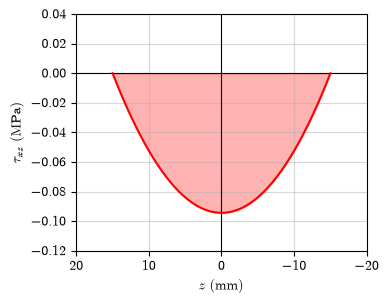

In [16]:
tau_Vz_vals = tau_Vz_num(z_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(z_vals, tau_Vz_vals, color='red', zorder=5)
plt.fill_between(z_vals, tau_Vz_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$z ~ \mathrm{(mm)}$')
plt.ylabel(r'$\tau_{xz} ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-20, 20)
plt.ylim(-0.12, 0.04)
plt.tight_layout()
plt.gca().invert_xaxis()
plt.savefig('csusztatofeszultseg_Vz.pdf')
plt.show()

##### $M_{hy}$ hajlító igénybevételből

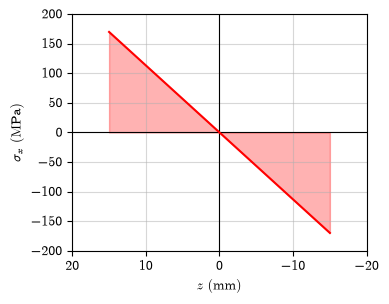

In [17]:
sigma_Mhy_vals = sigma_Mhy_num(z_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(z_vals, sigma_Mhy_vals, color='red', zorder=5)
plt.fill_between(z_vals, sigma_Mhy_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$z ~ \mathrm{(mm)}$')
plt.ylabel(r'$\sigma_{x} ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-20, 20)
plt.ylim(-200, 200)
plt.tight_layout()
plt.gca().invert_xaxis()
plt.savefig('normalfeszultseg_Mhy.pdf')
plt.show()

##### $N$ normál igénybevételből

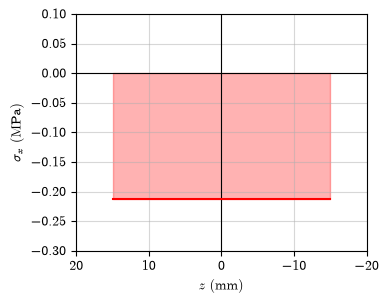

In [18]:
sigma_N_vals = np.full_like(z_vals, float(sigma_N))

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(z_vals, sigma_N_vals, color='red', zorder=5)
plt.fill_between(z_vals, sigma_N_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$z ~ \mathrm{(mm)}$')
plt.ylabel(r'$\sigma_{x} ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-20, 20)
plt.ylim(-0.3, 0.1)
plt.tight_layout()
plt.gca().invert_xaxis()
plt.savefig('normalfeszultseg_N.pdf')
plt.show()

##### $M_{hz}$ hajlító igénybevételből

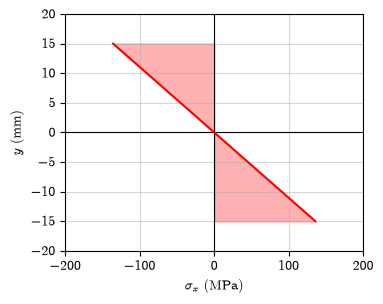

In [19]:
sigma_Mhz_vals = sigma_Mhz_num(y_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(sigma_Mhz_vals, y_vals, color='red', zorder=5)
plt.fill_betweenx(y_vals, sigma_Mhz_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\sigma_{x} ~ \mathrm{(MPa)}$')
plt.ylabel(r'$y ~ \mathrm{(mm)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-200, 200)
plt.ylim(-20, 20)
plt.tight_layout()
plt.savefig('normalfeszultseg_Mhz.pdf')
plt.show()

##### $V_y$ nyíró igénybevételből

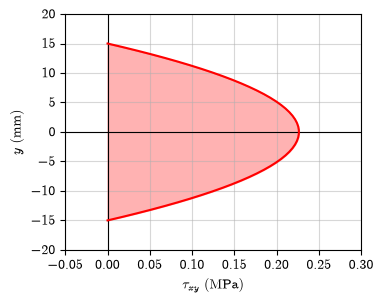

In [20]:
tau_Vy_vals = tau_Vy_num(y_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(tau_Vy_vals, y_vals, color='red', zorder=5)
plt.fill_betweenx(y_vals, tau_Vy_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\tau_{xy} ~ \mathrm{(MPa)}$')
plt.ylabel(r'$y ~ \mathrm{(mm)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-0.05, 0.3)
plt.ylim(-20, 20)
plt.tight_layout()
plt.savefig('csusztatofeszultseg_Vy.pdf')
plt.show()

##### $M_t$ csavaró igénybevételből

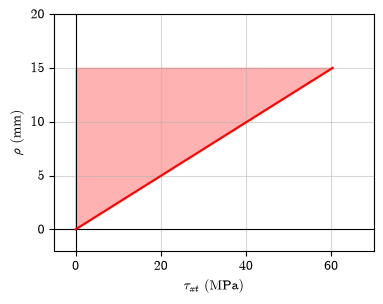

In [21]:
tau_Mt_vals = tau_Mt_num(rho_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(tau_Mt_vals, rho_vals, color='red', zorder=5)
plt.fill_betweenx(rho_vals, tau_Mt_vals, 0, color='red', alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\tau_{xt} ~ \mathrm{(MPa)}$')
plt.ylabel(r'$\rho ~ \mathrm{(mm)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-5, 70)
plt.ylim(-2, 20)
plt.tight_layout()
plt.savefig('csusztatofeszultseg_Mt.pdf')
plt.show()

<img src="img/03.jpg" alt="Feladat" width=600px>

#### Feszültségi állapot a $P_1 - P_5$ pontokban

A csavarásból adódó csúsztatófeszültség érintő irányú, ennek komponensei:

$$\tau_{xy}^{(M_t)} = -\frac{M_t}{I_p} \cdot z, \qquad \tau_{xz}^{(M_t)} = \frac{M_t}{I_p} \cdot y$$

In [22]:
def feszultsegi_allapot(y_P, z_P, nev):
    # Normálfeszültség
    s_N = sigma_N
    s_Mhz = sigma_Mhz.subs(y, y_P)
    s_Mhy = sigma_Mhy.subs(z, z_P)
    s_x = s_N + s_Mhz + s_Mhy
    display(Math(rf'\sigma_x = \sigma_x^{{(N)}} + \sigma_x^{{(M_{{hz}})}} + \sigma_x^{{(M_{{hy}})}} = {latex(round(s_N, 3))} + ({latex(round(s_Mhz, 3))}) + ({latex(round(s_Mhy, 3))}) = {latex(round(s_x, 3))} ~\mathrm{{MPa}}'))

    # Csúsztatófeszültség (xy)
    t_Vy = tau_Vy.subs(y, y_P)
    t_Mt_xy = -M_t / I_p * z_P
    t_xy = t_Vy + t_Mt_xy
    display(Math(rf'\tau_{{xy}} = \tau_{{xy}}^{{(V_y)}} + \tau_{{xy}}^{{(M_t)}} = {latex(round(t_Vy, 3))} + ({latex(round(t_Mt_xy, 3))}) = {latex(round(t_xy, 3))} ~\mathrm{{MPa}}'))

    # Csúsztatófeszültség (xz)
    t_Vz = tau_Vz.subs(z, z_P)
    t_Mt_xz = M_t / I_p * y_P
    t_xz = t_Vz + t_Mt_xz
    display(Math(rf'\tau_{{xz}} = \tau_{{xz}}^{{(V_z)}} + \tau_{{xz}}^{{(M_t)}} = {latex(round(t_Vz, 3))} + ({latex(round(t_Mt_xz, 3))}) = {latex(round(t_xz, 3))} ~\mathrm{{MPa}}'))

    # Feszültségi tenzor
    sigma_P = sp.Matrix([[s_x, t_xy, t_xz],
                         [t_xy, 0, 0],
                         [t_xz, 0, 0]])
    display(Math(rf'\underline{{\underline{{\sigma}}}}_{{{nev}}} = {latex(sigma_P.applyfunc(lambda e: round(e, 3)))} ~\mathrm{{MPa}}'))

    return sigma_P

##### $P_1$ pont: $y = -r, ~ z = 0$

In [23]:
sigma_P1 = feszultsegi_allapot(-r, 0, 'P_1')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/04.jpg" alt="Feladat" width=300px>

##### $P_2$ pont: $y = 0, ~ z = -r$

In [24]:
sigma_P2 = feszultsegi_allapot(0, -r, 'P_2')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/05.jpg" alt="Feladat" width=300px>

##### $P_3$ pont: $y = r, ~ z = 0$

In [25]:
sigma_P3 = feszultsegi_allapot(r, 0, 'P_3')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/06.jpg" alt="Feladat" width=300px>

##### $P_4$ pont: $y = 0, ~ z = r$

In [26]:
sigma_P4 = feszultsegi_allapot(0, r, 'P_4')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/07.jpg" alt="Feladat" width=300px>

##### $P_5$ pont: $y = 0, ~ z = 0$

In [27]:
sigma_P5 = feszultsegi_allapot(0, 0, 'P_5')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/08.jpg" alt="Feladat" width=300px>

#### Ferde hajlítás

Az $M_{hy}$ és $M_{hz}$ hajlítás egybe is kezelhető $\rightarrow$ kör esetén minden súlyponti tengely főtengely $\rightarrow$ egyenes hajlítás.

<img src="img/09.jpg" alt="Feladat" width=300px>

##### Eredő hajlítónyomaték

In [28]:
M_hxi = sp.sqrt(M_hy**2 + M_hz**2)
display(Math(rf'M_{{h\xi}} = \sqrt{{M_{{hy}}^2 + M_{{hz}}^2}} = {latex(round(M_hxi / 10**3, 3))} ~\mathrm{{Nm}}'))

# A xi tengely y tengellyel bezárt szöge
alpha = sp.atan(M_hz / M_hy)
display(Math(rf'\mathrm{{tan}}(\alpha) = \frac{{M_{{hz}}}}{{M_{{hy}}}} \quad \longrightarrow \quad \alpha = {latex(round(sp.deg(alpha), 2))}^\circ'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Keresztmetszeti jellemzők

In [29]:
I_xi = I_y
display(Math(rf'I_\xi = I_y = {latex(round(I_xi, 3))} ~\mathrm{{mm^4}}'))

K_xi = K_y
display(Math(rf'K_\xi = K_y = {latex(round(K_xi, 3))} ~\mathrm{{mm^3}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Hajlításból adódó normálfeszültség

In [30]:
zeta = sp.Symbol('zeta')

sigma_Mh = M_hxi / I_xi * zeta
display(Math(rf'\sigma_x^{{(M_h)}}(\zeta) = \frac{{M_{{h\xi}}}}{{I_\xi}} \cdot \zeta = {latex(sigma_Mh.evalf(4))} ~[\mathrm{{MPa}}], ~ ha ~ \zeta~[\mathrm{{mm}}]'))

# Maximális érték a szélső szálban
sigma_Mh_max = M_hxi / K_xi
display(Math(rf'\sigma_{{x,\mathrm{{max}}}}^{{(M_h)}} = \sigma_x^{{(M_h)}}(\zeta=d/2) = \frac{{M_{{h\xi}}}}{{K_\xi}} = {latex(round(sigma_Mh_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Maximális feszültség (abszolút értékben), a $P$ pontban ébred

In [31]:
sigma_max = -sigma_Mh_max + sigma_N
display(Math(rf'\sigma_x^P = \sigma_\mathrm{{max}} = -\sigma_{{x,\mathrm{{max}}}}^{{(M_h)}} + \sigma_x^{{(N)}} = {latex(round(sigma_max, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

##### $P$ pont helye: $\xi = 0, ~ \zeta = -d/2$

In [32]:
y_P = r * sp.sin(alpha)
display(Math(rf'y_P = \frac{{d}}{{2}} \cdot \mathrm{{sin}}(\alpha) = {latex(round(y_P, 3))} ~\mathrm{{mm}}'))

z_P = -r * sp.cos(alpha)
display(Math(rf'z_P = -\frac{{d}}{{2}} \cdot \mathrm{{cos}}(\alpha) = {latex(round(z_P, 3))} ~\mathrm{{mm}}'))

# Ellenőrzés az y-z koordináta-rendszerben felírt feszültségekkel
sigma_P = sigma_N + sigma_Mhz.subs(y, y_P) + sigma_Mhy.subs(z, z_P)
display(Math(rf'\sigma_x(y_P, z_P) = {latex(round(sigma_P, 3))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Zérustengely

In [33]:
# Eredő normálfeszültség
sigma_eredo = sigma_Mh + sigma_N
display(Math(rf'\sigma_x(\zeta) = {latex(sigma_eredo.evalf(4))}'))

# Ahol a feszültség zérus
eq = sigma_eredo
sol = sp.solve(eq, zeta)
zeta_sol = sol[0]
display(Math(rf'\zeta^* = {latex(round(zeta_sol, 4))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

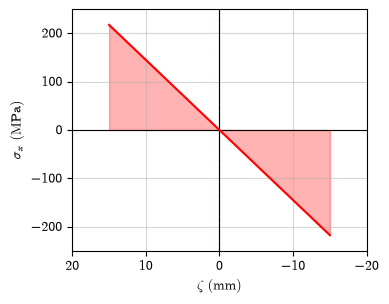

In [34]:
sigma_eredo_num = sp.lambdify(zeta, sigma_eredo, modules='numpy')

zeta_vals = np.linspace(-r, r)
sigma_eredo_vals = sigma_eredo_num(zeta_vals)

plt.figure(figsize=(10/2.54, 8/2.54))
plt.plot(zeta_vals, sigma_eredo_vals, color='red', zorder=5)
plt.fill_between(zeta_vals, sigma_eredo_vals, 0, color='red', alpha=0.3)
plt.axvline(float(zeta_sol), color='green', linestyle='--', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\zeta ~ \mathrm{(mm)}$')
plt.ylabel(r'$\sigma_{x} ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.xlim(-20, 20)
plt.ylim(-250, 250)
plt.tight_layout()
plt.gca().invert_xaxis()
plt.savefig('normalfeszultseg_eredo.pdf')
plt.show()

<img src="img/10.jpg" alt="Feladat" width=500px>